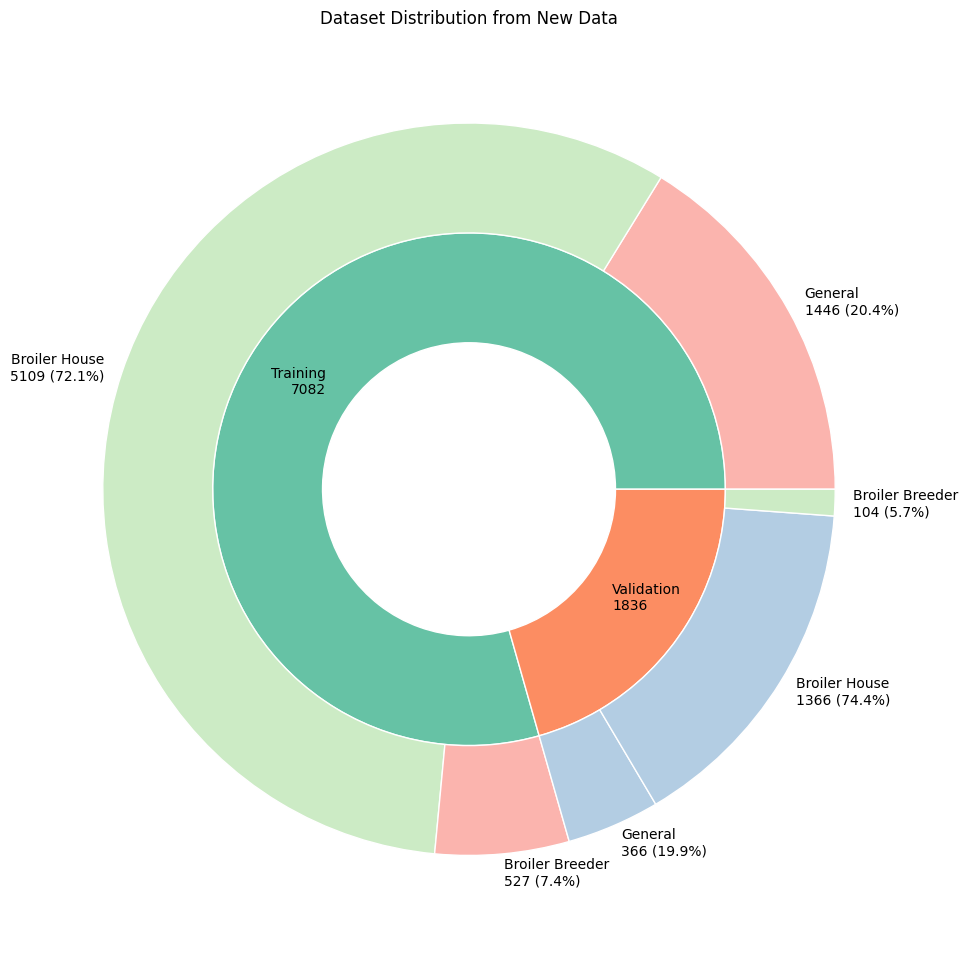

In [4]:
# Preparing data as per the user's provided image
data_new = {
    'Dataset': ['Training', 'Validation', 'Training', 'Training', 'Validation', 'Validation'],
    'Category': ['General', 'General', 'Broiler House', 'Broiler Breeder', 'Broiler House', 'Broiler Breeder'],
    'Count': [1446, 366, 5109, 527, 1366, 104]
}

df_new = pd.DataFrame(data_new)

# Visualization similar to the previous nested pie chart
fig, ax = plt.subplots(figsize=(10, 10))
size = 0.3

# Inner Ring (Dataset level)
inner_vals = df_new.groupby('Dataset')['Count'].sum()
inner_labels = [f"{label}\n{count}" for label, count in zip(inner_vals.index, inner_vals)]
inner_colors = sns.color_palette("Set2", len(inner_labels))

ax.pie(inner_vals, radius=1-size, labels=inner_labels, labeldistance=0.7, colors=inner_colors,
       wedgeprops=dict(width=size, edgecolor='w'))

# Outer Ring (Category Level)
outer_labels = []
outer_vals = []
outer_colors = []

for dataset, total in inner_vals.items():
    subset = df_new[df_new['Dataset'] == dataset]
    subset_colors = sns.color_palette("Pastel1", len(subset))
    for idx, row in subset.iterrows():
        pct = (row['Count'] / total) * 100
        outer_labels.append(f"{row['Category']}\n{row['Count']} ({pct:.1f}%)")
        outer_vals.append(row['Count'])
        outer_colors.append(subset_colors[idx % len(subset_colors)])

ax.pie(outer_vals, radius=1, labels=outer_labels, colors=outer_colors,
       wedgeprops=dict(width=size, edgecolor='w'), labeldistance=1.05)

ax.set(aspect="equal", title='Dataset Distribution from New Data')
plt.tight_layout()
plt.show()


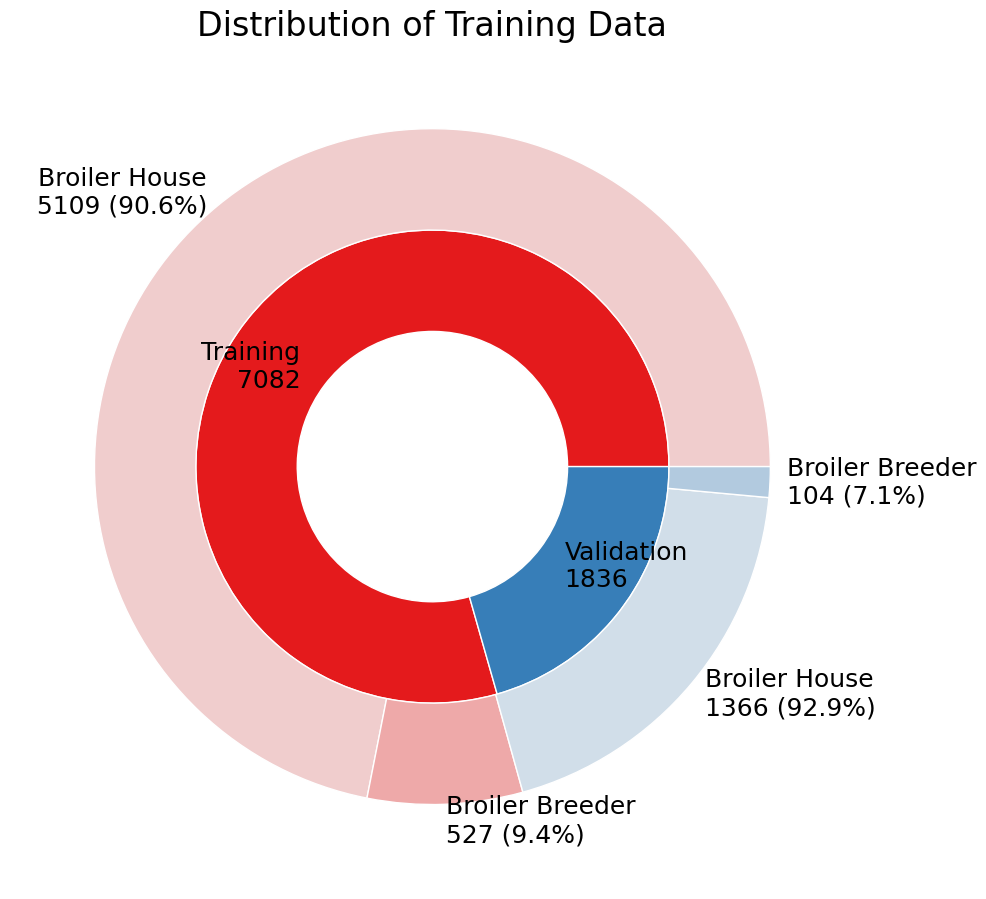

In [35]:
# Adjusting outer ring colors with distinct shades per category within each dataset
fig, ax = plt.subplots(figsize=(10, 10))
size = 0.3

# Inner Ring
inner_vals = df_new.groupby('Dataset')['Count'].sum()
inner_labels = [f"{label}\n{count}" for label, count in zip(inner_vals.index, inner_vals)]
inner_colors = sns.color_palette("Set1", len(inner_labels))

ax.pie(inner_vals, radius=1-size, labels=inner_labels, labeldistance=0.7, colors=inner_colors,
       wedgeprops=dict(width=size, edgecolor='w'), textprops={'fontsize':18})

# Outer Ring with distinct shades for each category
outer_labels = []
outer_vals = []
outer_colors = []

for i, (dataset, total) in enumerate(inner_vals.items()):
    subset = df_new[(df_new['Dataset'] == dataset) & (df_new['Category'] != 'General')]
    subset_total = subset['Count'].sum()
    # Generate different shades based on inner color
    subset_colors = sns.light_palette(inner_colors[i], n_colors=len(subset)+5, reverse=False)[1:]
    for idx, (j, row) in enumerate(subset.iterrows()):
        pct = (row['Count'] / subset_total) * 100
        outer_labels.append(f"{row['Category']}\n{row['Count']} ({pct:.1f}%)")
        outer_vals.append(row['Count'])
        outer_colors.append(subset_colors[idx])

ax.pie(outer_vals, radius=1, labels=outer_labels, colors=outer_colors,
       wedgeprops=dict(width=size, edgecolor='w'), labeldistance=1.05, textprops={'fontsize':18})

ax.set(aspect="equal")
ax.set_title('Distribution of Training Data', fontsize=24)
plt.tight_layout()
plt.show()
plt.savefig('training_distribution.png', transparent=True, dpi=300)

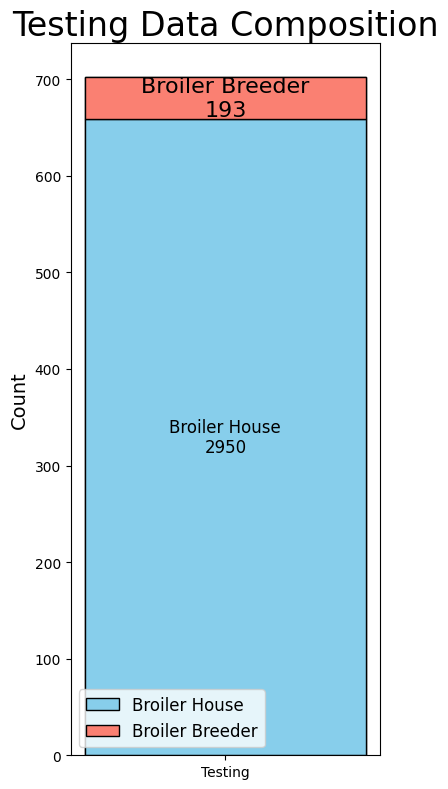

In [4]:
# Preparing data for the vertical bar visualization
testing_total = 702
broiler_house = 2950
broiler_breeder = 193

# Calculating ratios
total_broiler = broiler_house + broiler_breeder
house_ratio = broiler_house / total_broiler
breeder_ratio = broiler_breeder / total_broiler

# Creating plot
fig, ax = plt.subplots(figsize=(4, 8))

# Plotting bar for 'Testing'
ax.bar('Testing', testing_total, color='lightgrey', edgecolor='black', width=0.4)

# Overlay smaller bars representing ratios of Broiler House and Breeder
ax.bar('Testing', testing_total * house_ratio, color='skyblue', edgecolor='black', width=0.4, label='Broiler House')
ax.bar('Testing', testing_total * breeder_ratio, bottom=testing_total * house_ratio, color='salmon', edgecolor='black', width=0.4, label='Broiler Breeder')

# Adding labels and legend
ax.set_ylabel('Count', fontsize=14)
ax.set_title('Testing Data Composition', fontsize=24)
ax.legend(fontsize=12)

# Annotating the segments
ax.text(0, testing_total * house_ratio / 2, f'Broiler House\n{broiler_house}', ha='center', va='center', fontsize=12, color='black')
ax.text(0, testing_total * house_ratio + (testing_total * breeder_ratio / 2), f'Broiler Breeder\n{broiler_breeder}', ha='center', va='center', fontsize=16, color='black')

plt.tight_layout()
plt.show()


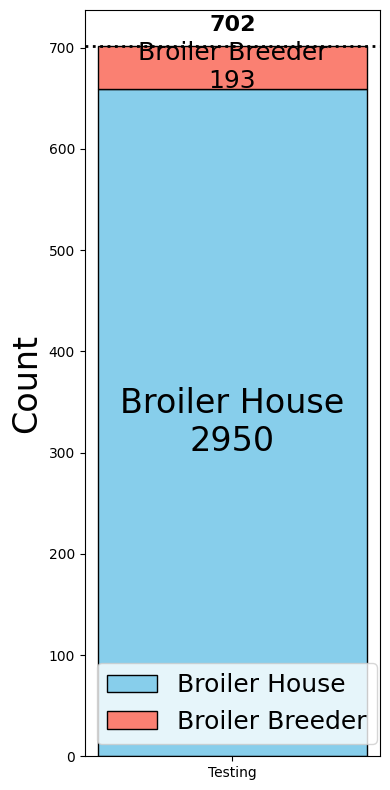

In [6]:
# Plotting again with the label on the dotted line exactly as "702"

fig, ax = plt.subplots(figsize=(4, 8))

# Bars for Broiler House and Breeder
ax.bar('Testing', testing_total * house_ratio, color='skyblue', edgecolor='black', width=0.4, label='Broiler House')
ax.bar('Testing', testing_total * breeder_ratio, bottom=testing_total * house_ratio, color='salmon', edgecolor='black', width=0.4, label='Broiler Breeder')

# Dotted line at 702 with label "702"
ax.axhline(702, color='black', linestyle='dotted', linewidth=2)
ax.text(0, 702 + 10, '702', ha='center', va='bottom', fontsize=16, fontweight='bold')

# Labels and annotations
ax.set_ylabel('Count', fontsize=24)
# ax.set_title('Testing Data', fontsize=24)
ax.legend(fontsize=18)

ax.text(0, testing_total * house_ratio / 2, f'Broiler House\n{broiler_house}', ha='center', va='center', fontsize=24, color='black')
ax.text(0, testing_total * house_ratio + (testing_total * breeder_ratio / 2), f'Broiler Breeder\n{broiler_breeder}', ha='center', va='center', fontsize=18, color='black')

plt.tight_layout()
plt.savefig('testing_distribution.png', transparent=True, dpi=300)
plt.show()


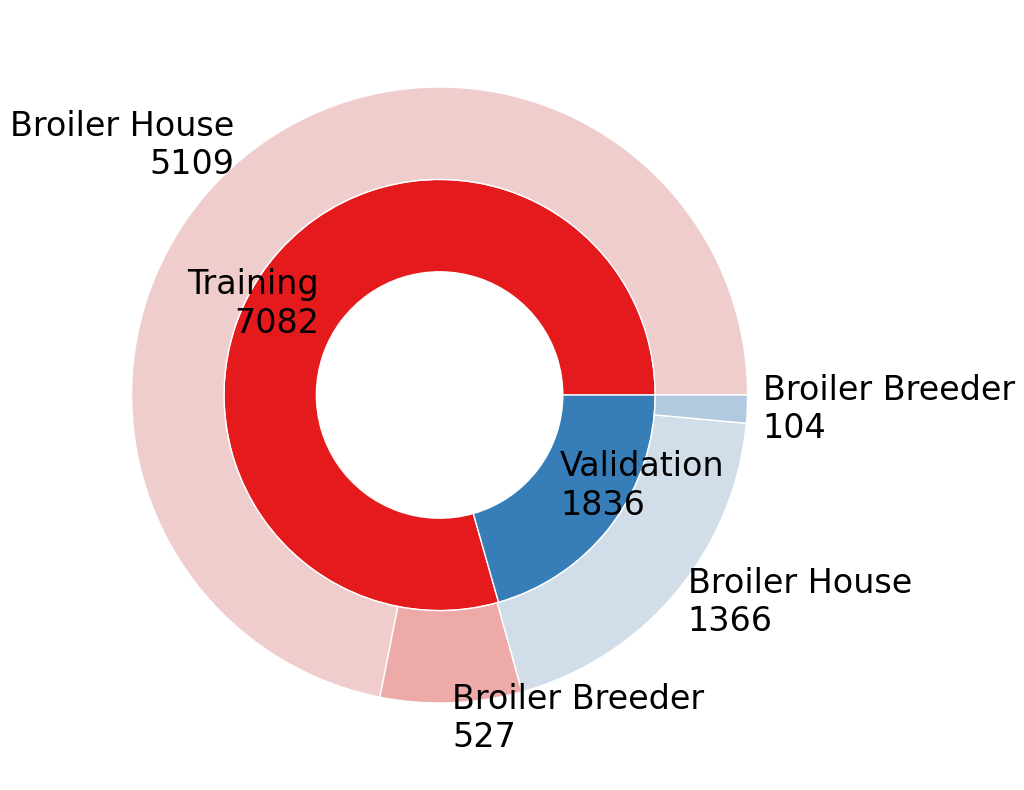

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sample DataFrame (replace with your actual df_new if different)
df_new = pd.DataFrame({
    'Dataset': ['Training', 'Validation', 'Training', 'Training', 'Validation', 'Validation'],
    'Category': ['General', 'General', 'Broiler House', 'Broiler Breeder', 'Broiler House', 'Broiler Breeder'],
    'Count': [1446, 366, 5109, 527, 1366, 104]
})

# Create figure and axes
fig, ax = plt.subplots(figsize=(10, 10))
size = 0.3

# Inner Ring
inner_vals = df_new.groupby('Dataset')['Count'].sum()
inner_labels = [f"{label}\n{count}" for label, count in zip(inner_vals.index, inner_vals)]
inner_colors = sns.color_palette("Set1", len(inner_labels))

ax.pie(inner_vals, radius=1-size, labels=inner_labels, labeldistance=0.7, colors=inner_colors,
       wedgeprops=dict(width=size, edgecolor='w'), textprops={'fontsize':24})

# Outer Ring without percentages
outer_labels = []
outer_vals = []
outer_colors = []

for i, (dataset, total) in enumerate(inner_vals.items()):
    subset = df_new[(df_new['Dataset'] == dataset) & (df_new['Category'] != 'General')]
    subset_total = subset['Count'].sum()
    # Generate different shades based on inner color
    subset_colors = sns.light_palette(inner_colors[i], n_colors=len(subset)+5, reverse=False)[1:]
    for idx, (j, row) in enumerate(subset.iterrows()):
        outer_labels.append(f"{row['Category']}\n{row['Count']}")  # No percentage here
        outer_vals.append(row['Count'])
        outer_colors.append(subset_colors[idx])

ax.pie(outer_vals, radius=1, labels=outer_labels, colors=outer_colors,
       wedgeprops=dict(width=size, edgecolor='w'), labeldistance=1.05, textprops={'fontsize':24})

# Final touches
ax.set(aspect="equal")
# ax.set_title('Distribution of Training Data', fontsize=24)

# Save the figure with transparent background
plt.savefig('training_distribution.png', transparent=True, dpi=300)

# Optional: display the figure
plt.show()


In [11]:
import pandas as pd

# Load the uploaded CSV file
file_path = "runs/segment/train30/results.csv"
df = pd.read_csv(file_path)

# Display the first few rows to understand the structure
df.head()

,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),...,metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,49.6815,1.36049,1.91524,2.15336,1.09719,0.94559,0.48447,0.49590,0.37096,...,0.48169,0.48748,0.31521,0.85206,1.12746,0.89673,0.87990,0.070263,0.003304,0.003304
1,2,94.3247,1.11943,1.32770,1.04200,0.95249,0.93157,0.47037,0.51984,0.33399,...,0.46271,0.49920,0.30240,1.02333,1.20451,0.95687,0.97064,0.040250,0.006624,0.006624
2,3,138.0080,1.17301,1.34984,1.10443,0.97545,0.92217,0.48305,0.49098,0.33773,...,0.45051,0.42427,0.21961,0.96933,1.70861,1.43825,0.95420,0.010224,0.009931,0.009931
3,4,181.6360,1.20917,1.40832,1.04438,0.98523,0.89120,0.45254,0.45847,0.30454,...,0.44068,0.43603,0.24316,1.05437,1.47457,1.43537,1.00413,0.009941,0.009941,0.009941
4,5,224.7230,1.14259,1.21346,0.96223,0.96765,0.42595,0.47983,0.53673,0.36994,...,0.47542,0.52476,0.30969,0.95943,1.16555,0.95106,0.95493,0.009921,0.009921,0.009921


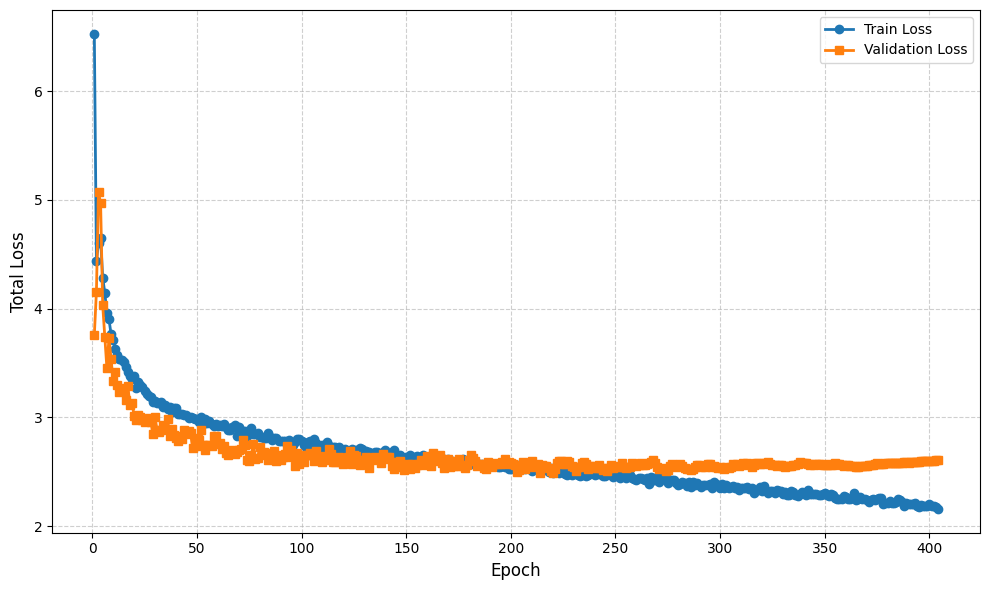

In [13]:
import matplotlib.pyplot as plt

# Combine train and val losses for plotting
df["train_total_loss"] = df["train/box_loss"] + df["train/seg_loss"] + df["train/cls_loss"] + df["train/dfl_loss"]
df["val_total_loss"] = df["val/box_loss"] + df["val/seg_loss"] + df["val/cls_loss"] + df["val/dfl_loss"]

# Plot
plt.figure(figsize=(10, 6))
plt.plot(df["epoch"], df["train_total_loss"], label="Train Loss", linewidth=2, marker='o')
plt.plot(df["epoch"], df["val_total_loss"], label="Validation Loss", linewidth=2, marker='s')

# plt.title("Training vs Validation Loss Over Epochs", fontsize=16)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Total Loss", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('total_lossVSepochs.png', transparent=True, dpi=300)
plt.show()


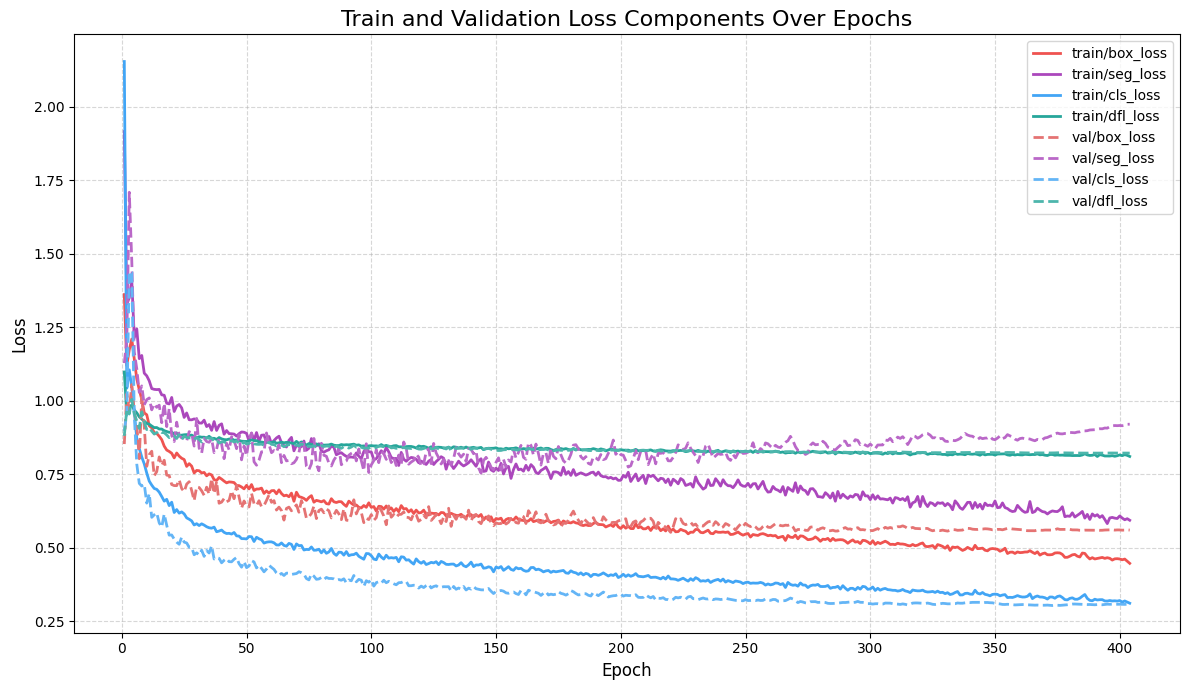

In [10]:
# Define a color palette inspired by Material Design
material_colors = {
    "train/box_loss": "#EF5350",  # Red
    "train/seg_loss": "#AB47BC",  # Purple
    "train/cls_loss": "#42A5F5",  # Blue
    "train/dfl_loss": "#26A69A",  # Teal
    "val/box_loss": "#E57373",    # Light Red
    "val/seg_loss": "#BA68C8",    # Light Purple
    "val/cls_loss": "#64B5F6",    # Light Blue
    "val/dfl_loss": "#4DB6AC",    # Light Teal
}

# Plot individual loss components
plt.figure(figsize=(12, 7))

# Plot training losses
for loss in ["train/box_loss", "train/seg_loss", "train/cls_loss", "train/dfl_loss"]:
    plt.plot(df["epoch"], df[loss], label=loss, linewidth=2, color=material_colors[loss])

# Plot validation losses
for loss in ["val/box_loss", "val/seg_loss", "val/cls_loss", "val/dfl_loss"]:
    plt.plot(df["epoch"], df[loss], label=loss, linewidth=2, linestyle='--', color=material_colors[loss])

plt.title("Train and Validation Loss Components Over Epochs", fontsize=16)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('lossVSepochs.png', transparent=True, dpi=300)
plt.show()


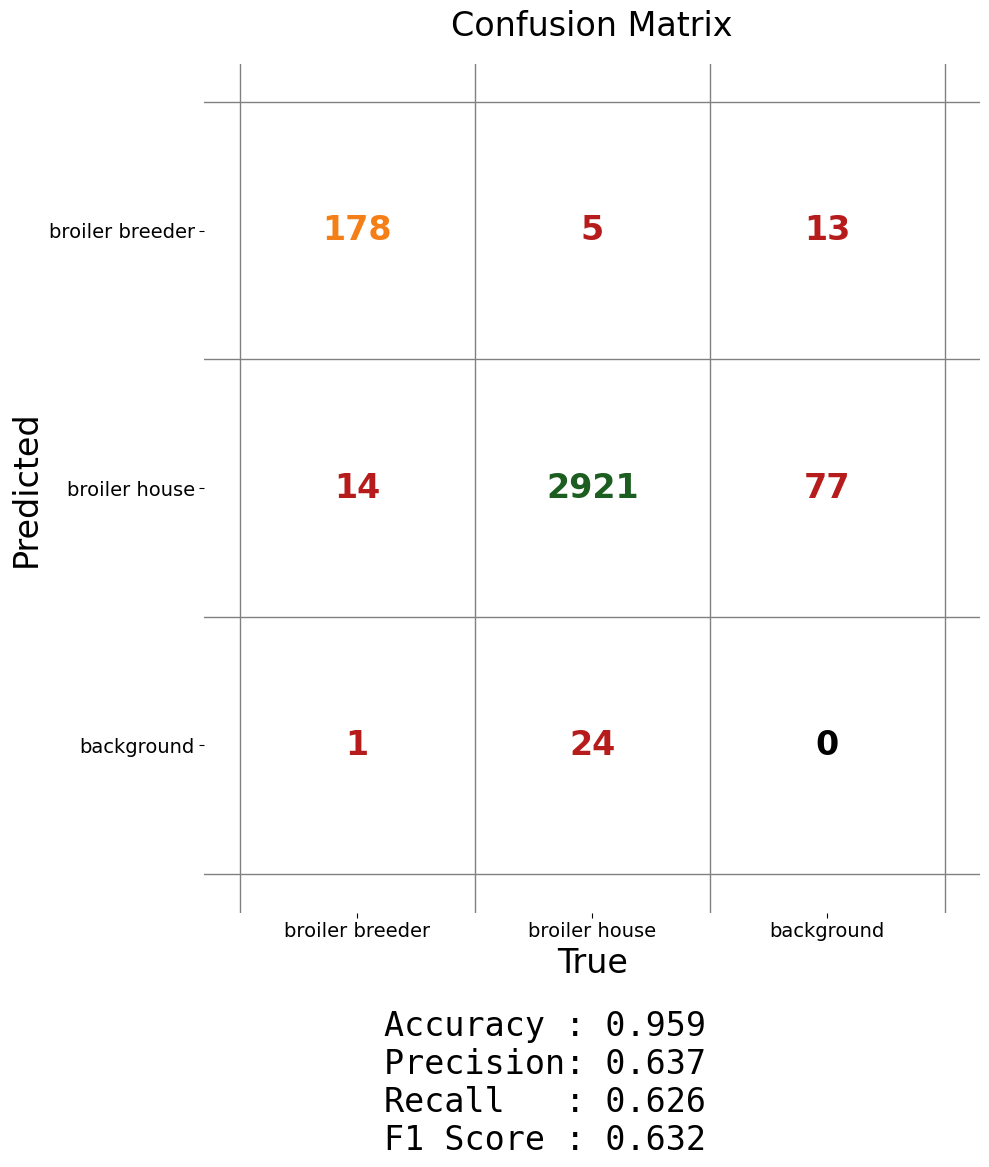

In [13]:
# Re-import necessary libraries after reset
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Reconstruct the confusion matrix and labels
conf_matrix = np.array([
    [178, 5, 13],
    [14, 2921, 77],
    [1, 24, 0]
])
labels = ['broiler breeder', 'broiler house', 'background']

# Flatten the confusion matrix into predictions and true labels
true_labels = []
pred_labels = []

for i in range(len(conf_matrix)):
    for j in range(len(conf_matrix[i])):
        true_labels += [i] * conf_matrix[i][j]
        pred_labels += [j] * conf_matrix[i][j]

# Calculate metrics
accuracy = accuracy_score(true_labels, pred_labels)
precision = precision_score(true_labels, pred_labels, average='macro')
recall = recall_score(true_labels, pred_labels, average='macro')
f1 = f1_score(true_labels, pred_labels, average='macro')

# Prepare the formatted metrics string
metrics_text = (
    f"Accuracy : {accuracy:.3f}\n"
    f"Precision: {precision:.3f}\n"
    f"Recall   : {recall:.3f}\n"
    f"F1 Score : {f1:.3f}"
)

# Define color function
def get_color(value):
    if value > 2000:
        return '#1b5e20'  # Dark green
    elif value > 100:
        return '#f57f17'  # Amber
    elif value > 0:
        return '#b71c1c'  # Dark red
    else:
        return '#000000'  # Black for zero

# Plot the confusion matrix and text below
plt.figure(figsize=(10, 10))
plt.title("Confusion Matrix", fontsize=24, pad=20)

for i in range(len(conf_matrix)):
    for j in range(len(conf_matrix[i])):
        value = conf_matrix[i][j]
        plt.text(j, i, str(value), ha='center', va='center',
                 fontsize=24, color=get_color(value), weight='bold')

# Draw grid
for i in range(len(labels)+1):
    plt.axhline(i-0.5, color='gray', linewidth=1)
    plt.axvline(i-0.5, color='gray', linewidth=1)

plt.xticks(range(len(labels)), labels, fontsize=14)
plt.yticks(range(len(labels)), labels, fontsize=14)
plt.xlabel("True", fontsize=24)
plt.ylabel("Predicted", fontsize=24)
plt.gca().invert_yaxis()
plt.box(False)

# Add metrics text below the matrix
plt.figtext(0.55, -0.15, metrics_text, wrap=True, horizontalalignment='center',
            fontsize=24, family='monospace')

plt.tight_layout()
plt.savefig('conf_matrix.png', transparent=True, dpi=300)
plt.show()


In [1]:
# # Re-import necessary libraries after code execution environment reset
# import matplotlib.pyplot as plt
# import numpy as np
# from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# # Reconstruct the confusion matrix and labels
# conf_matrix = np.array([
#     [178, 5, 13],
#     [14, 2921, 77],
#     [1, 24, 0]
# ])
# labels = ['broiler breeder', 'broiler house', 'background']

# # Flatten the confusion matrix into predictions and true labels
# true_labels = []
# pred_labels = []

# for i in range(len(conf_matrix)):
#     for j in range(len(conf_matrix[i])):
#         true_labels += [i] * conf_matrix[i][j]
#         pred_labels += [j] * conf_matrix[i][j]

# # Calculate metrics
# accuracy = accuracy_score(true_labels, pred_labels)
# precision = precision_score(true_labels, pred_labels, average='macro')
# recall = recall_score(true_labels, pred_labels, average='macro')
# f1 = f1_score(true_labels, pred_labels, average='macro')

# # Prepare the formatted metrics string
# metrics_text = (
#     f"Accuracy : {accuracy:.3f}\n"
#     f"Precision: {precision:.3f}\n"
#     f"Recall   : {recall:.3f}\n"
#     f"F1 Score : {f1:.3f}"
# )

# # Plot confusion matrix manually with colorful cells and text metrics
# plt.figure(figsize=(12, 8))
# plt.title("Confusion Matrix", fontsize=20, pad=20)

# # Define colors for each cell value range
# def get_color(value):
#     if value > 2000:
#         return '#1b5e20'  # Dark green
#     elif value > 100:
#         return '#f57f17'  # Amber
#     elif value > 0:
#         return '#b71c1c'  # Dark red
#     else:
#         return '#000000'  # Black for zero

# # Plot the confusion matrix cells
# for i in range(len(conf_matrix)):
#     for j in range(len(conf_matrix[i])):
#         value = conf_matrix[i][j]
#         plt.text(j, i, str(value), ha='center', va='center',
#                  fontsize=18, color=get_color(value), weight='bold')

# # Draw grid lines
# for i in range(len(labels)+1):
#     plt.axhline(i-0.5, color='gray', linewidth=1)
#     plt.axvline(i-0.5, color='gray', linewidth=1)

# plt.xticks(range(len(labels)), labels, fontsize=16)
# plt.yticks(range(len(labels)), labels, fontsize=16)
# plt.xlabel("True", fontsize=16)
# plt.ylabel("Predicted", fontsize=16)
# plt.gca().invert_yaxis()
# plt.box(False)

# # Display the performance metrics on the side
# plt.text(3.1, 1.0, metrics_text, fontsize=16, verticalalignment='center', family='monospace')

# plt.tight_layout()
# plt.savefig('conf_matrix.png', transparent=True, dpi=300)
# plt.show()
